# Part 1 – Python & Data Foundations

## Project Overview

The goal of this section is to prepare the raw appointment data for analysis and machine learning.

I will complete the following tasks:

- **Task 1.1 – CSV Foundations:** Read the CSV file, convert data types, separate accepted and rejected rows, and save rejected records in JSON format.
- **Task 1.2 – Data Inspection:** Explore the dataset, check missing values and duplicates, and clean inconsistent booking channels and dates.
- **Task 1.3 – Data Cleaning:** Handle invalid values, fill missing data, and cap outliers using the IQR method.
- **Task 1.4 – Feature Engineering:** Create `lead_days` and `no_show` features and perform NumPy calculations.
- **Task 1.5 – API Enrichment:** Fetch clinic temperature data using the Open-Meteo API.
- **Task 1.6 – Export and SQL:** Save the cleaned datasets, perform quality checks, and generate SQL INSERT statements.

**Final Objective:** To create clean, reliable and enriched datasets that can be used for further analysis and no-show prediction.

In [5]:
# @title Importing important libraries
import csv
import json
import numpy as np
import pandas as pd
import requests

### Task 1.1 – Read the CSV File Using Python

In this task, I use Python's built-in `csv` module to read the appointment data. I convert the required columns into numeric data types using `parse_row()`, separate accepted and rejected rows using `try/except`, and save rejected records in `rejected_rows.json` using JSON.

In [6]:
#  write a function to convert come column to integers
def parse_row(row):
  row['age'] = int(row['age'])
  row['fee_inr'] = int(row['fee_inr'])
  row['prior_no_shows'] = int(row['prior_no_shows'])
  row['distance_km'] = float(row['distance_km'])
  return row

accepted = []
rejected = []
# importing the "appoinments.csv" file using ** with open **

with open("/content/qDCCmpyfss1kBJJB.csv", mode = "r",newline ="") as files:
  # Read the CSV using csv.DictReader
  reader = csv.DictReader(files)
  rows = list(reader)
   # Print the "header"
  print(reader.fieldnames)
   #  print the "row_count"
  print(f"Row count is {len(rows)}")
  for row in rows:
    try:
     cleaned_row = parse_row(row)
     accepted.append(cleaned_row)
    except ValueError:
     rejected.append(row)

print(f"Accepted row count is {len(accepted)}")
print(f"Rejected row count is {len(rejected)}")

['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date', 'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel', 'visit_type', 'reminder_sent', 'prior_no_shows', 'status']
Row count is 1020
Accepted row count is 988
Rejected row count is 32


In [7]:
with open("rejected_rows.json", "w") as file:
    json.dump(rejected, file, indent=2)

### Task 1.2 – Inspect and Clean the Dataset

Here, I load the original CSV file using Pandas and inspect its shape, columns, data types, missing values and duplicates. I then remove duplicate rows, standardise booking channel names, convert date columns and remove rows with missing appointment dates or status.

In [8]:
# loading dataset and print the fisrt 5 rows
df = pd.read_csv("/content/qDCCmpyfss1kBJJB.csv")
df.head()

,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status
0,A0001,P509,C05,2025-01-24,2025-01-25,60.0,F,18.0,850,Phone,Consultation,Yes,1,No-Show
1,A0002,P046,C07,2025-05-27,2025-06-06,39.0,M,12.5,350,Walk-in,Follow-up,No,2,Attended
2,A0003,P009,C02,2025-03-24,2025-03-30,63.0,F,4.1,850,Walk-in,Consultation,No,0,Attended
3,A0003,P009,C02,2025-03-24,2025-03-30,63.0,F,4.1,850,Walk-in,Consultation,No,0,Attended
4,A0004,P482,C01,2025-04-18,2025-04-22,52.0,F,7.5,750,App,Consultation,Yes,0,Attended


In [9]:
print(f"There are {df.shape[0]} rows and {df.shape[1]} columns in our dataset")

There are 1020 rows and 14 columns in our dataset


In [10]:
# columns in our data
df.columns

Index(['appointment_id', 'patient_id', 'clinic_id', 'booked_on', 'appt_date',
       'age', 'gender', 'distance_km', 'fee_inr', 'booking_channel',
       'visit_type', 'reminder_sent', 'prior_no_shows', 'status'],
      dtype='object')

In [11]:
# Information about the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   appointment_id   1020 non-null   object 
 1   patient_id       1020 non-null   object 
 2   clinic_id        1020 non-null   object 
 3   booked_on        1020 non-null   object 
 4   appt_date        1019 non-null   object 
 5   age              1008 non-null   float64
 6   gender           1020 non-null   object 
 7   distance_km      1000 non-null   float64
 8   fee_inr          1020 non-null   int64  
 9   booking_channel  1020 non-null   object 
 10  visit_type       1020 non-null   object 
 11  reminder_sent    1020 non-null   object 
 12  prior_no_shows   1020 non-null   int64  
 13  status           1016 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 111.7+ KB


In [12]:
# Description about our data
df.describe()

,age,distance_km,fee_inr,prior_no_shows
count,1008.000000,1000.000000,1020.000000,1020.000000
mean,48.467262,9.998300,649.362745,0.628431
std,18.979446,11.008159,341.836071,0.944056
min,-4.000000,0.600000,300.000000,0.000000
25%,33.000000,4.600000,500.000000,0.000000
50%,48.000000,8.200000,650.000000,0.000000
75%,63.000000,13.100000,800.000000,1.000000
max,250.000000,221.000000,7500.000000,5.000000


In [13]:
# missing values
df.isnull().sum()

,0
appointment_id,0
patient_id,0
clinic_id,0
booked_on,0
appt_date,1
age,12
gender,0
distance_km,20
fee_inr,0
booking_channel,0


In [14]:
df.isnull().any()

,0
appointment_id,False
patient_id,False
clinic_id,False
booked_on,False
appt_date,True
age,True
gender,False
distance_km,True
fee_inr,False
booking_channel,False


In [15]:
# unique values
print(f' Total Unique values :{df.nunique()}')

 Total Unique values :appointment_id     1000
patient_id          456
clinic_id             8
booked_on           201
appt_date           185
age                  66
gender                2
distance_km         187
fee_inr              18
booking_channel      16
visit_type            2
reminder_sent         2
prior_no_shows        6
status                2
dtype: int64


In [16]:
# row count
print(" row count:", len(df))

 row count: 1020


In [17]:
# @title visualization in "appoinments.csv" before cleaning
import seaborn as sns
import matplotlib.pyplot as plt

/tmp/ipykernel_1377/3754582362.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="gender", palette="Set2")


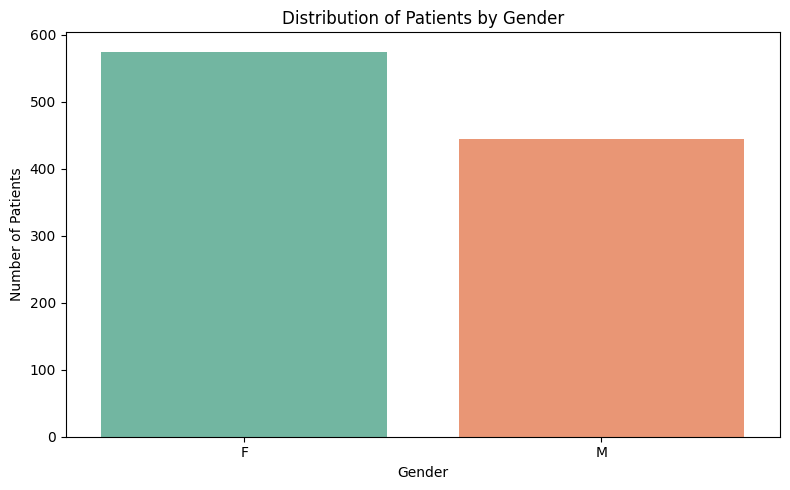

In [18]:
# creat the bar chart showing numbers of patients for each gender
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="gender", palette="Set2")

plt.title("Distribution of Patients by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1377/1798308135.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="booking_channel", palette="Set2")


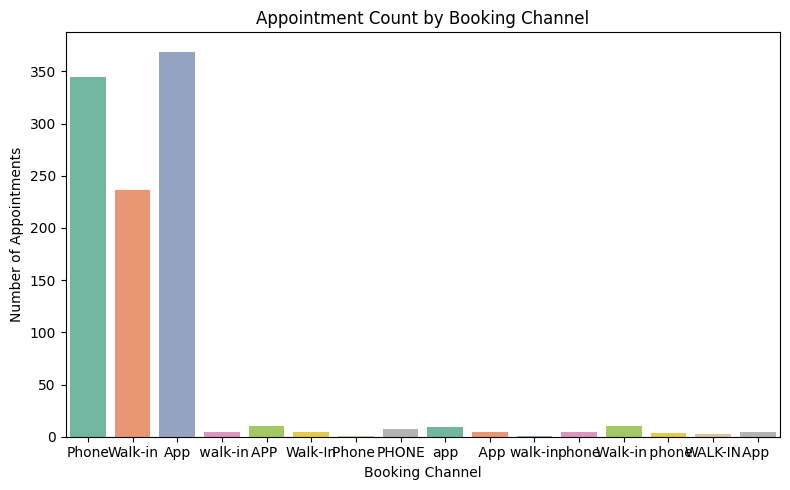

In [19]:
# plot appoinments by booking channel
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="booking_channel", palette="Set2")

plt.title("Appointment Count by Booking Channel")
plt.xlabel("Booking Channel")
plt.ylabel("Number of Appointments")

plt.tight_layout()
plt.show()

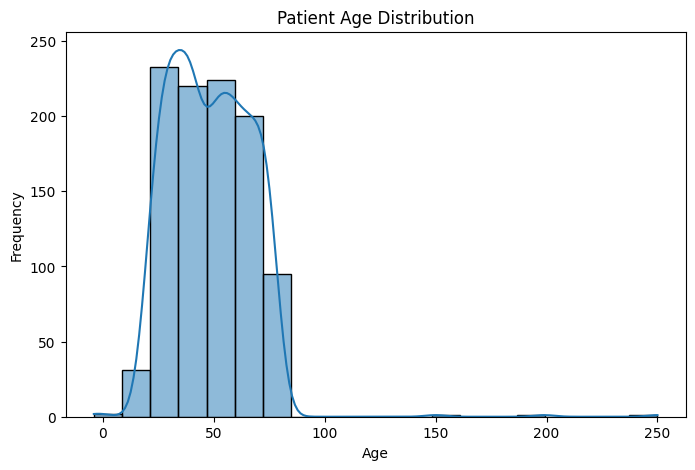

In [20]:
# patient age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

/tmp/ipykernel_1377/967611684.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="visit_type", y="age", palette="Set2")


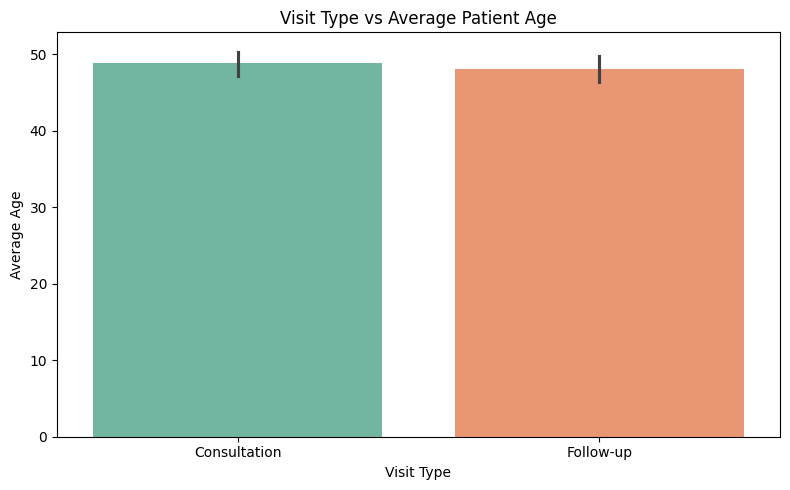

In [21]:
# compare avg age bye visit
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="visit_type", y="age", palette="Set2")

plt.title("Visit Type vs Average Patient Age")
plt.xlabel("Visit Type")
plt.ylabel("Average Age")

plt.tight_layout()
plt.show()

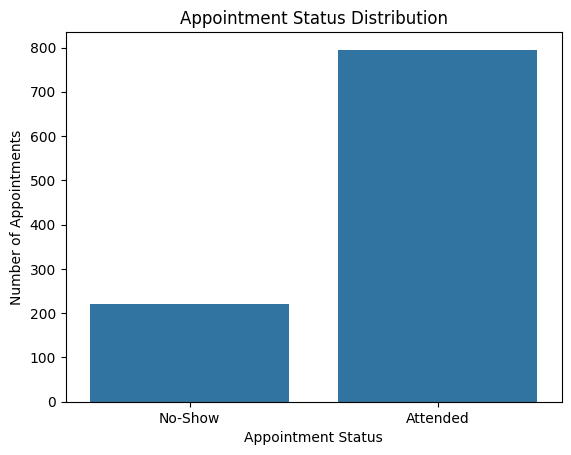

In [22]:
#  appoinments status counts
sns.countplot(data=df, x="status")

plt.title("Appointment Status Distribution")
plt.xlabel("Appointment Status")
plt.ylabel("Number of Appointments")
plt.show()

/tmp/ipykernel_1377/3536882325.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="reminder_sent", y="fee_inr", palette="Set2")


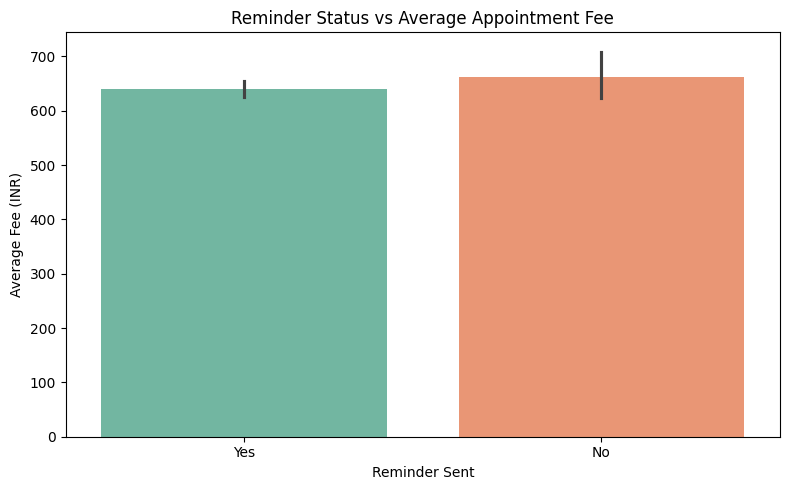

In [23]:
# avg fee by reminder
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="reminder_sent", y="fee_inr", palette="Set2")

plt.title("Reminder Status vs Average Appointment Fee")
plt.xlabel("Reminder Sent")
plt.ylabel("Average Fee (INR)")

plt.tight_layout()
plt.show()

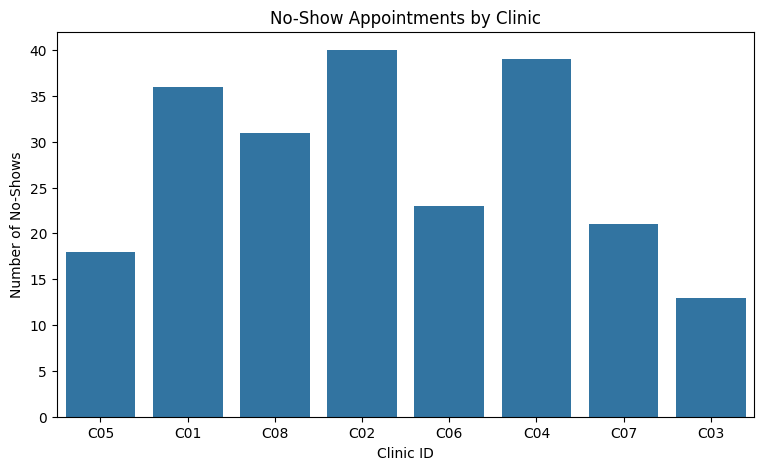

In [24]:
# no-show appointments by clinic
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df[df["status"] == "No-Show"],
    x="clinic_id"
)

plt.title("No-Show Appointments by Clinic")
plt.xlabel("Clinic ID")
plt.ylabel("Number of No-Shows")
plt.show()

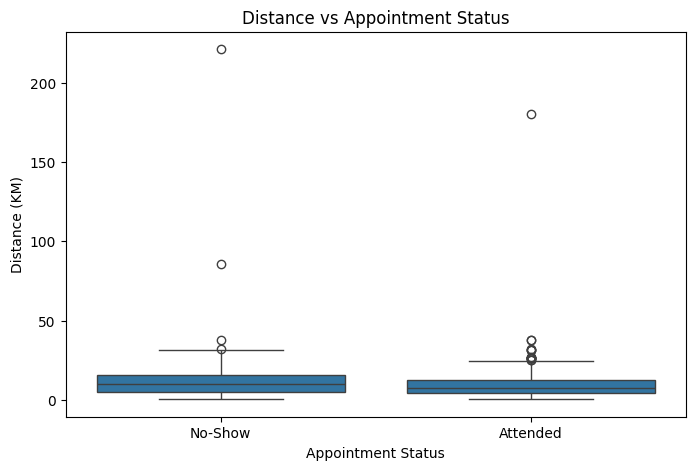

In [25]:
# compare travel distacne by status
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="status", y="distance_km")

plt.title("Distance vs Appointment Status")
plt.xlabel("Appointment Status")
plt.ylabel("Distance (KM)")
plt.show()

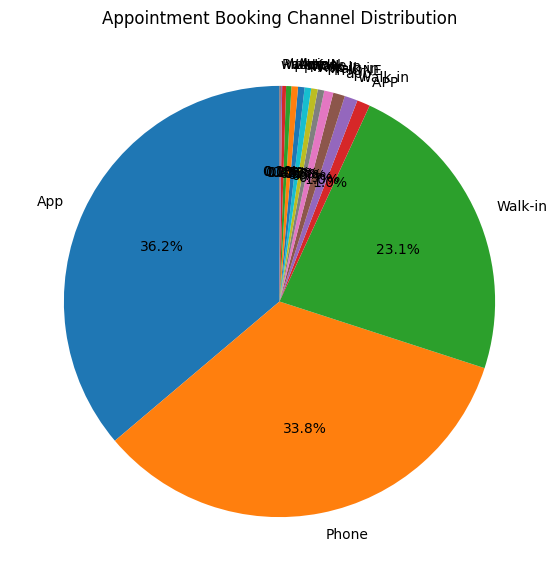

In [26]:
#  conut bookings by each channel
channel_counts = df["booking_channel"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    channel_counts,
    labels=channel_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Appointment Booking Channel Distribution")
plt.show()

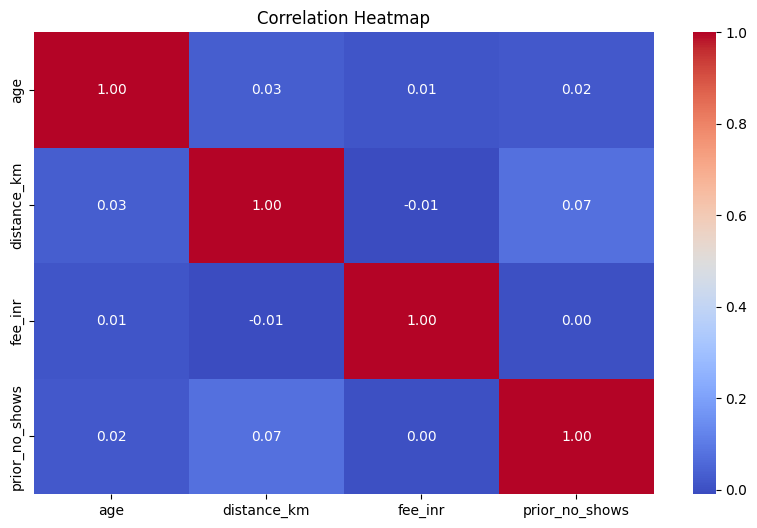

In [27]:
# Numeric feature correlation heatmap
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include="number")

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

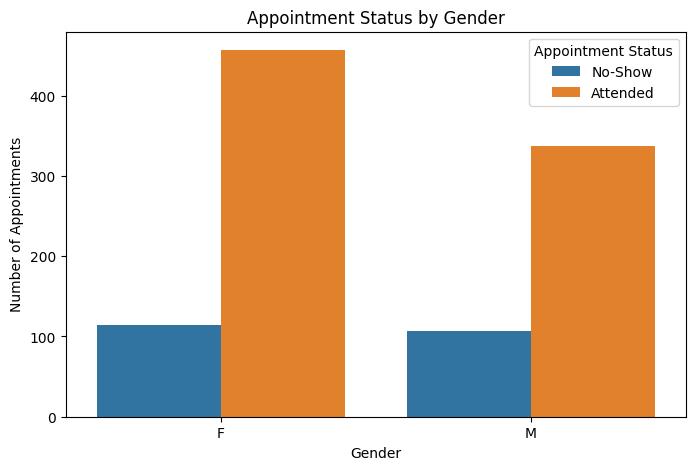

In [28]:
# appoinment ststus by gender
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="status"
)

plt.title("Appointment Status by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Appointments")
plt.legend(title="Appointment Status")

plt.show()

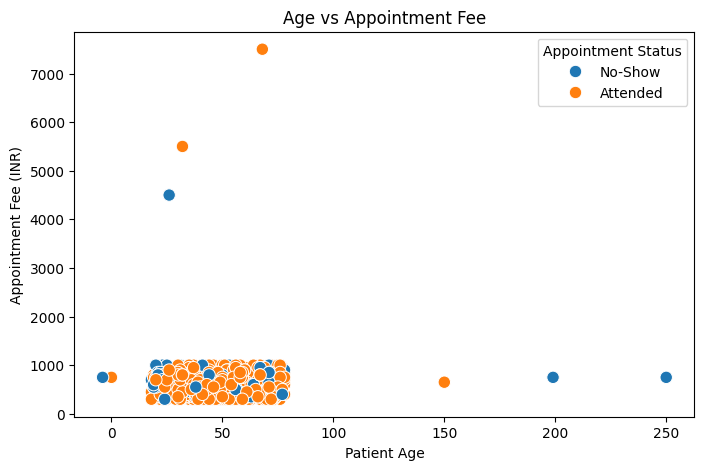

In [29]:
# age vs appoinments fee
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="fee_inr",
    hue="status",
    s=80
)

plt.title("Age vs Appointment Fee")
plt.xlabel("Patient Age")
plt.ylabel("Appointment Fee (INR)")
plt.legend(title="Appointment Status")
plt.show()

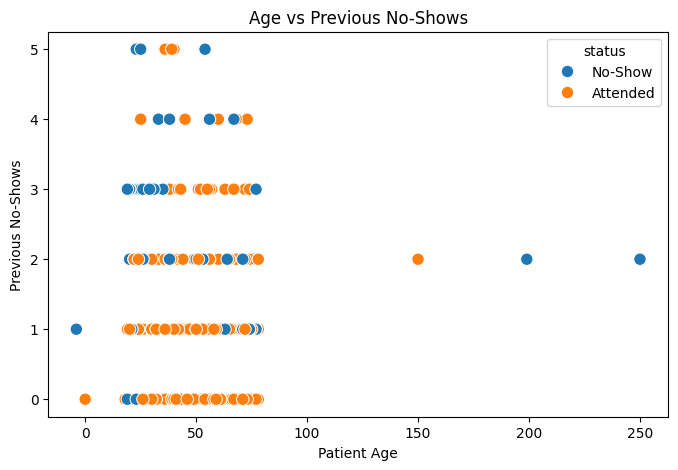

In [30]:
# age vs prevoius no-shows
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="prior_no_shows",
    hue="status",
    s=80
)

plt.title("Age vs Previous No-Shows")
plt.xlabel("Patient Age")
plt.ylabel("Previous No-Shows")
plt.show()

In [31]:
# 1. Drop exact duplicate rows
print(f"Total Duplicates values : {df.duplicated().sum()}")
df= df.drop_duplicates()
print(f"After dropping duplicates : {len(df)}")

Total Duplicates values : 20
After dropping duplicates : 1000


In [32]:
# 2. Clean "booking_channel"
df['booking_channel'] = df['booking_channel'].str.strip().str.title()
print("Unique booking channels:", df['booking_channel'].nunique())
print("After cleaning booking_channel:", len(df))

Unique booking channels: 3
After cleaning booking_channel: 1000


In [33]:
# 3. Convert dates
df['appt_date'] = pd.to_datetime(df['appt_date'],errors="coerce")
df['booked_on'] = pd.to_datetime(df['booked_on'])
print("After converting dates:", len(df))

After converting dates: 1000


In [34]:
df[["appt_date","booked_on"]].head()

,appt_date,booked_on
0,2025-01-25,2025-01-24
1,2025-06-06,2025-05-27
2,2025-03-30,2025-03-24
4,2025-04-22,2025-04-18
5,2025-01-02,2024-11-23


In [35]:
# 4. Drop rows with missing appt_date or status
df = df.dropna(subset=["appt_date","status"])
print("After dropping missing appt_date/status:", len(df))
print("\nCurrent shape:", df.shape)

After dropping missing appt_date/status: 990

Current shape: (990, 14)


### Task 1.3 – Handle Invalid Values, Missing Data and Outliers

In this task, I identify invalid ages and replace them with missing values. I fill missing age and distance values using their medians. Then I calculate Q1, Q3 and IQR to cap outliers using `np.clip()`. Finally, I round distance and fee values.

In [36]:
# 5. Invalid ages become missing
invalid_age = (df['age'] < 1 ) | (df['age'] > 100)
print(invalid_age.sum())
df.loc[invalid_age, 'age'] = np.nan

5


In [37]:
# 6. Fill missing age with the median
df['age'] = df['age'].fillna(df['age'].median()).round().astype(int)
df['distance_km'] = df['distance_km'].fillna(df['distance_km'].median())

In [38]:
df[['age', 'distance_km']].head()

,age,distance_km
0,60,18.0
1,39,12.5
2,63,4.1
4,52,7.5
5,64,19.0


In [39]:
# 7. Compute IQR fences AFTER filling gaps, then cap outliers
def cap_outliers(dataframe, column):
    q1 = dataframe[column].quantile(0.25)
    q3 = dataframe[column].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    capped_count = ((dataframe[column] < lower_fence) | (dataframe[column] > upper_fence)).sum()

    dataframe[column] = np.clip(dataframe[column],lower_fence,upper_fence)

    print(f"\n{column}")
    print(f"Q1: {q1}")
    print(f"Q3: {q3}")
    print(f"IQR: {iqr}")
    print(f"Lower fence: {lower_fence}")
    print(f"Upper fence: {upper_fence}")
    print(f"Values capped: {capped_count}")

    return capped_count


distance_capped = cap_outliers(df, "distance_km")
fee_capped = cap_outliers(df, "fee_inr")


# #  This is a another and simple methord but it's a bit of messy code so we use the function "cap_outliers(dataframe, column)" methord

#  for "distance_km"


# q1_distance = df['distance_km'].quantile(0.25)
# q3_distance = df['distance_km'].quantile(0.75)
# iqr_distance = q3_distance - q1_distance

# lower_bound_distance = q1_distance - 1.5 * iqr_distance
# upper_bound_distance = q3_distance + 1.5 * iqr_distance

# capped_count = ((df['distance_km'] < lower_bound_distance) | (df['distance_km'] > upper_bound_distance)).sum()
# df['distance_km'] = np.clip(df['distance_km'], lower_bound_distance, upper_bound_distance )

# print("\ndistance_km")
# print(f"Q1: {q1_distance}")
# print(f"Q3: {q3_distance}")
# print(f"IQR: {iqr_distance}")
# print(f"Lower Bound: {lower_bound_distance}")
# print(f"Upper Bound: {upper_bound_distance}")
# print(f"Values capped: {capped_count}")

# for "free_inr"

# q1_free_inr = df['fee_inr'].quantile(0.25)
# q3_free_inr = df['fee_inr'].quantile(0.75)
# iqr_free_inr = q3_free_inr - q1_free_inr

# lower_bound_free_inr = q1_free_inr - 1.5 * iqr_free_inr
# upper_bound_free_inr = q3_free_inr + 1.5 * iqr_free_inr

# capped_count = ((df['fee_inr']< lower_bound_free_inr) |(df['fee_inr']> upper_bound_free_inr)).sum()
# df['fee_inr'] = np.clip(df['fee_inr'], lower_bound_free_inr, upper_bound_free_inr )

# print("\nfree_inr")
# print(f"Q1: {q1_free_inr}")
# print(f"Q3: {q3_free_inr}")
# print(f"IQR: {iqr_free_inr}")
# print(f"Lower Bound: {lower_bound_free_inr}")
# print(f"Upper Bound: {upper_bound_free_inr}")
# print(f"Values capped: {capped_count}")


distance_km
Q1: 4.625
Q3: 13.0
IQR: 8.375
Lower fence: -7.9375
Upper fence: 25.5625
Values capped: 26

fee_inr
Q1: 500.0
Q3: 787.5
IQR: 287.5
Lower fence: 68.75
Upper fence: 1218.75
Values capped: 3


In [40]:
# Round values
df["distance_km"] = df["distance_km"].round(1)
df["fee_inr"] = df["fee_inr"].round().astype(int)

print("Summary:")
print("distance_km values capped:", distance_capped)
print("fee_inr values capped:", fee_capped)

Summary:
distance_km values capped: 26
fee_inr values capped: 3


### Task 1.4 – Feature Engineering and NumPy Analysis

I create two new columns: `lead_days` to calculate the number of days between booking and appointment, and `no_show` to represent no-shows as 1 and other appointments as 0. I then use NumPy to calculate column means, identify bookings made more than 14 days in advance and detect distance outliers using z-scores.

In [41]:
# create new column "lead_days"
df['lead_days'] = (df['appt_date'] - df['booked_on']).dt.days
df['lead_days'].head()
# create a column "no_show"
df["no_show"] = (df['status'] == "No-Show").astype(int)

In [42]:
print("Minimum lead days:", df['lead_days'].min())
print("Maximum lead days:", df['lead_days'].max())

print("Total no-shows:", df['no_show'].sum())
print("No-show percentage:", (df['no_show'].mean() * 100).round(1))

Minimum lead days: 1
Maximum lead days: 45
Total no-shows: 218
No-show percentage: 22.0


In [43]:
# Create NumPy matrix
X = df[["age", "distance_km", "fee_inr", "lead_days"]].to_numpy()

#  Mean of each column without loops
columns = X.mean(axis=0)
print("Column means:")
for column, mean_value in zip(
    ["age", "distance_km", "fee_inr", "lead_days"],
    columns
):
    print(f"{column}: {mean_value}")

Column means:
age: 48.173737373737374
distance_km: 9.50090909090909
fee_inr: 635.7141414141414
lead_days: 11.819191919191919


In [44]:
#  Number and share of rows
mask = df["lead_days"]> 14

print("Lead days > 14:")
print("Count:", mask.sum())
print("Share:", mask.mean())

Lead days > 14:
Count: 296
Share: 0.298989898989899


In [45]:
#  Z-scores for distance_km and count where |z| > 2
x = df['distance_km']
z_score = (x - np.mean(x)) / np.std(x)
print("Z-score for distance(km):")
print(z_score)

outliers_count = (np.abs(z_score) > 2).sum()
print("\nNumber of outliers:", outliers_count)

Z-score for distance(km):
0       1.380349
1       0.487087
2      -0.877169
4      -0.324970
5       1.542761
          ...   
1015    0.568292
1016    1.282903
1017   -1.023340
1018    2.614676
1019    0.210987
Name: distance_km, Length: 990, dtype: float64

Number of outliers: 53


### Task 1.5 – Enrich Clinic Data Using Open-Meteo API

In this task, I load the clinic dataset and use the Open-Meteo API to fetch temperature information for each clinic. I use a retry mechanism to handle failed requests and save the temperature data along with the original clinic information in `clinics_enriched.csv`.

In [48]:
#  loading the clinics file
df2 = pd.read_csv("/content/jbFzPdd2gB2Ex2TY.csv")
df2

,clinic_id,clinic_name,city,tier,latitude,longitude
0,C01,Kothrud Family Clinic,Pune,Metro,18.5074,73.8077
1,C02,Hadapsar Care Centre,Pune,Metro,18.5089,73.9260
2,C03,Sitabuldi Health Point,Nagpur,Tier-2,21.1458,79.0882
3,C04,Malviya Nagar Clinic,Jaipur,Tier-2,26.8553,75.8150
4,C05,Vaishali Nagar Clinic,Jaipur,Tier-2,26.9124,75.7873
5,C06,Edappally Medical Centre,Kochi,Tier-2,10.0261,76.3085
6,C07,Vijay Nagar Clinic,Indore,Tier-2,22.7533,75.8937
7,C08,Gomti Nagar Care Point,Lucknow,Tier-2,26.8467,80.9462


In [49]:
# calling the free Open-Meteo API
API_URL = "https://api.open-meteo.com/v1/forecast"

In [50]:
def get_temperature(df2):
  for attempts in range(2):
     try:
      # calling API
        response = requests.get(API_URL,
                            params={"latitude": df2['latitude'], "longitude": df2['longitude'],
                                    "hourly": "temperature_2m",
                                    "forecast_days": 1},
                            timeout= 10)
        # cheak if status code = 200
        if response.status_code == 200:
          # read the data in json
          data = response.json()
          # Check if temperature data exists
          if "hourly" in data and "temperature_2m" in data["hourly"]:
            return data["hourly"]["temperature_2m"][0]
            print(f"Temperature data missing for {df2_row['clinic_name']}")
          else:
            print(f"API failed with status {response.status_code} for {df2_row['clinic_name']}")
          # get ths first value
          temp_c = data["hourly"]["temperature_2m"][0]
       # If status is not 200 or data is missing
        print(f"Attempt {attempts + 1} failed for {df2['clinic_name']}")
     except requests.exceptions.RequestException as e:
      print(f"Request error for {df2['clinic_name']}: {e}")
# If both attempts fail
  print(f"Could not get temperature for {df2['clinic_name']}")
  return None

In [51]:
temperature = []

# temp for every clinic
for _, clinic in df2.iterrows():
    # Get temperature
    temp = get_temperature(clinic)
    # Add temperature to the list
    temperature.append(temp)

# create a new column
df2['temp_c'] = temperature

# Save the new file
df2.to_csv("clinics_enriched.csv", index=False)

# Show result
print("\nSaved clinics_enriched.csv")
print(df2)


Saved clinics_enriched.csv
  clinic_id               clinic_name     city    tier  latitude  longitude  \
0       C01     Kothrud Family Clinic     Pune   Metro   18.5074    73.8077   
1       C02      Hadapsar Care Centre     Pune   Metro   18.5089    73.9260   
2       C03    Sitabuldi Health Point   Nagpur  Tier-2   21.1458    79.0882   
3       C04      Malviya Nagar Clinic   Jaipur  Tier-2   26.8553    75.8150   
4       C05     Vaishali Nagar Clinic   Jaipur  Tier-2   26.9124    75.7873   
5       C06  Edappally Medical Centre    Kochi  Tier-2   10.0261    76.3085   
6       C07        Vijay Nagar Clinic   Indore  Tier-2   22.7533    75.8937   
7       C08    Gomti Nagar Care Point  Lucknow  Tier-2   26.8467    80.9462   

   temp_c  
0    19.2  
1    19.5  
2    19.8  
3    16.4  
4    16.4  
5    25.8  
6    16.4  
7    14.4  


### Task 1.6 – Export Clean Data and Generate SQL

I sort the appointment records by `appointment_id`, format the date columns and select the required 16 columns. I check that appointment IDs are unique and that there are no missing values before saving `appointments_clean.csv`. Finally, I generate SQL INSERT statements for clinics first and appointments second.

In [52]:
# Sort "appointment_id"
df = df.sort_values("appointment_id").copy()

df['appt_date'] = df['appt_date'].dt.strftime('%Y-%m-%d')
df['booked_on'] = df['booked_on'].dt.strftime('%Y-%m-%d')
df.head()

,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
4,A0004,P482,C01,2025-04-18,2025-04-22,52,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
5,A0005,P251,C01,2024-11-23,2025-01-02,64,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1


In [53]:
final_columns = [
    "appointment_id",
    "patient_id",
    "clinic_id",
    "booked_on",
    "appt_date",
    "age",
    "gender",
    "distance_km",
    "fee_inr",
    "booking_channel",
    "visit_type",
    "reminder_sent",
    "prior_no_shows",
    "status",
    "lead_days",
    "no_show"
]
clean_df = df[final_columns].copy()

In [54]:
# Checks before exporting
print("appointment_id is unique:", clean_df["appointment_id"].is_unique)
missing_counts = clean_df.isnull().sum()
print("\nMissing values in the 16 columns:")
print(missing_counts)


if not clean_df["appointment_id"].is_unique:
    raise ValueError("appointment_id is not unique")

if missing_counts.sum() != 0:
    raise ValueError("One or more of the 16 export columns has missing values")

appointment_id is unique: True

Missing values in the 16 columns:
appointment_id     0
patient_id         0
clinic_id          0
booked_on          0
appt_date          0
age                0
gender             0
distance_km        0
fee_inr            0
booking_channel    0
visit_type         0
reminder_sent      0
prior_no_shows     0
status             0
lead_days          0
no_show            0
dtype: int64


In [55]:
# Save clean appointments table
clean_df.to_csv("appointments_clean.csv", index=False)
print("Saved appointments_clean.csv")

Saved appointments_clean.csv


In [56]:
# creating a funtion for text
def sql_text(value):
    if pd.isna(value):
        return "NULL"
    if isinstance(value, str):
        return f"'{value}'"
    return str(value)

# creating a funtion for number as str without surronding quotes, ensuring sql reads as a number
def sql_number(value):
    if pd.isna(value):
        return "NULL"
    return str(value)

In [57]:
with open("load_data.sql", "w", encoding="utf-8") as file:

    # 1. Clinics INSERT statements FIRST
    for _, row in df2.iterrows():
        values = [
            sql_text(row["clinic_id"]),
            sql_text(row["clinic_name"]),
            sql_text(row["city"]),
            sql_text(row["tier"]),
            sql_number(row["latitude"]),
            sql_number(row["longitude"]),
            sql_number(row["temp_c"])]
        sql = ("INSERT INTO clinics VALUES (" + ",".join(values)+ ");\n")
        file.write(sql)
    file.write("\n")

    # 2. Appointments INSERT statements
    for _, row in clean_df.iterrows():
        values = [
            sql_text(row["appointment_id"]),
            sql_text(row["patient_id"]),
            sql_text(row["clinic_id"]),
            sql_text(row["booked_on"]),
            sql_text(row["appt_date"]),
            sql_number(row["age"]),
            sql_text(row["gender"]),
            sql_number(row["distance_km"]),
            sql_number(row["fee_inr"]),
            sql_text(row["booking_channel"]),
            sql_text(row["visit_type"]),
            sql_text(row["reminder_sent"]),
            sql_number(row["prior_no_shows"]),
            sql_text(row["status"]),
            sql_number(row["lead_days"]),
            sql_number(row["no_show"])]

        sql = ("INSERT INTO appointments VALUES (" + ",".join(values) + ");\n" )

        file.write(sql)

print("Saved load_data.sql")

Saved load_data.sql


### Final Verification and Clinic Summary

Finally, I reload the cleaned appointment file and create a clinic-wise summary. I calculate the total appointments, number of no-shows and no-show percentage for each clinic to understand which clinics have higher no-show rates.

In [58]:
df3 = pd.read_csv("/content/appointments_clean.csv")
df.head()

,appointment_id,patient_id,clinic_id,booked_on,appt_date,age,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,A0001,P509,C05,2025-01-24,2025-01-25,60,F,18.0,850,Phone,Consultation,Yes,1,No-Show,1,1
1,A0002,P046,C07,2025-05-27,2025-06-06,39,M,12.5,350,Walk-In,Follow-up,No,2,Attended,10,0
2,A0003,P009,C02,2025-03-24,2025-03-30,63,F,4.1,850,Walk-In,Consultation,No,0,Attended,6,0
4,A0004,P482,C01,2025-04-18,2025-04-22,52,F,7.5,750,App,Consultation,Yes,0,Attended,4,0
5,A0005,P251,C01,2024-11-23,2025-01-02,64,F,19.0,700,Phone,Consultation,No,0,No-Show,40,1


In [59]:
# @title Visualization/ checking in "appoinments_clean.csv" after cleaning

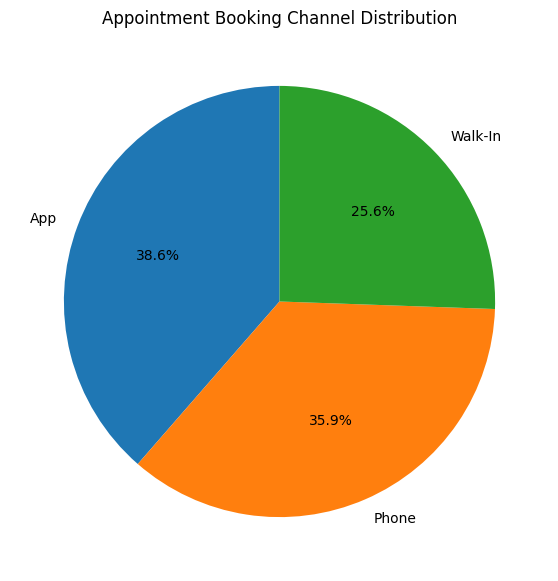

In [60]:
channel_counts = df["booking_channel"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    channel_counts,
    labels=channel_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Appointment Booking Channel Distribution")
plt.show()

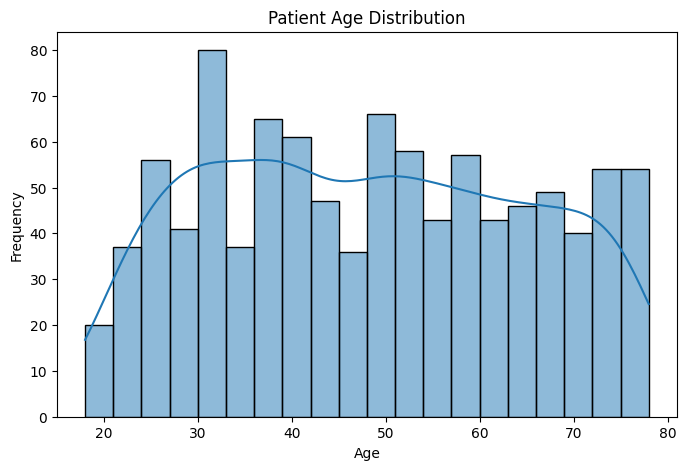

In [61]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

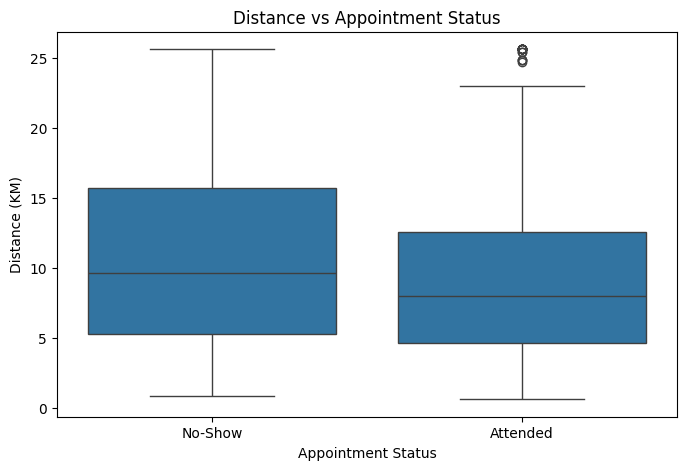

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="status", y="distance_km")

plt.title("Distance vs Appointment Status")
plt.xlabel("Appointment Status")
plt.ylabel("Distance (KM)")
plt.show()

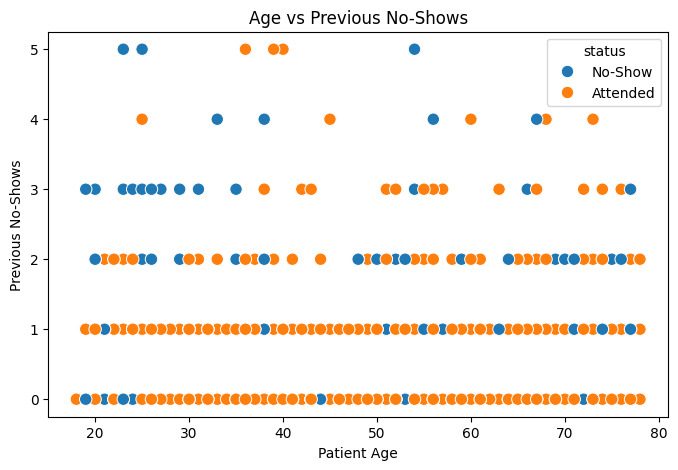

In [63]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="prior_no_shows",
    hue="status",
    s=80
)

plt.title("Age vs Previous No-Shows")
plt.xlabel("Patient Age")
plt.ylabel("Previous No-Shows")
plt.show()

In [64]:
# matching the anser with mysql by python

# Group data by clinic
clinic_summary = (df.groupby("clinic_id").agg(appointments=("appointment_id", "count"), no_shows=("no_show", "sum")).reset_index())

# Calculate no-show_pct
clinic_summary["no_show_pct"] = (100 * clinic_summary["no_shows"]/ clinic_summary["appointments"]).round(1)

# Sort no_show_pct by ascending
clinic_summary = clinic_summary.sort_values("no_show_pct",ascending=False)

print("-"*15 ,"clinic_summary" ,"-"*20, "\n")
print(clinic_summary)

--------------- clinic_summary -------------------- 

  clinic_id  appointments  no_shows  no_show_pct
7       C08            90        30         33.3
1       C02           143        39         27.3
3       C04           142        38         26.8
0       C01           160        36         22.5
6       C07           101        21         20.8
5       C06           142        23         16.2
2       C03            82        13         15.9
4       C05           130        18         13.8
